# Workshop-3 — Pasos 3 y 4: Ingeniería de características y modelo de regresión

**Qué pide el taller:**
- **Paso 3:** estadísticas descriptivas y visualizaciones, seleccionar y justificar las características, evitar la fuga del objetivo, tratar datos categóricos si hace falta y escalar si se requiere.
- **Paso 4:** dividir los datos 70% / 30%, entrenar un modelo de regresión simple, evaluarlo (MAE, RMSE, R²) y guardarlo como `model.pkl`.

**Entrada:** `data/processed/happiness_unified.csv` (resultado de `data_cleaning.ipynb`)
**Salida:** `models/model.pkl`

> El taller aclara que el foco es la integración del pipeline, no la optimización del modelo. Por eso se usa un modelo simple.

## 1. Cargar el dataset unificado

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/processed/happiness_unified.csv")
print(df.shape)
df.head()

(782, 9)


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
0,Switzerland,2015,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,7.587
1,Iceland,2015,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,7.561
2,Denmark,2015,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,7.527
3,Norway,2015,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,7.522
4,Canada,2015,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,7.427


## 2. Estadísticas descriptivas

In [2]:
df.describe().round(3)

,year,gdp,family,health,freedom,generosity,corruption,happiness_score
count,782.000,782.000,782.000,782.000,782.000,782.000,782.000,782.000
mean,2016.994,0.916,1.078,0.612,0.411,0.219,0.125,5.379
std,1.417,0.407,0.330,0.248,0.153,0.122,0.106,1.127
min,2015.000,0.000,0.000,0.000,0.000,0.000,0.000,2.693
25%,2016.000,0.606,0.869,0.440,0.310,0.130,0.054,4.510
50%,2017.000,0.982,1.125,0.647,0.431,0.202,0.091,5.322
75%,2018.000,1.236,1.327,0.808,0.531,0.279,0.156,6.190
max,2019.000,2.096,1.644,1.141,0.724,0.838,0.552,7.769


## 3. Relación de cada variable con el puntaje de felicidad

La **correlación** es un número entre -1 y 1 que mide qué tanto se mueven juntas dos variables. Cerca de 1: cuando una sube, la otra también. Cerca de 0: no hay relación lineal.

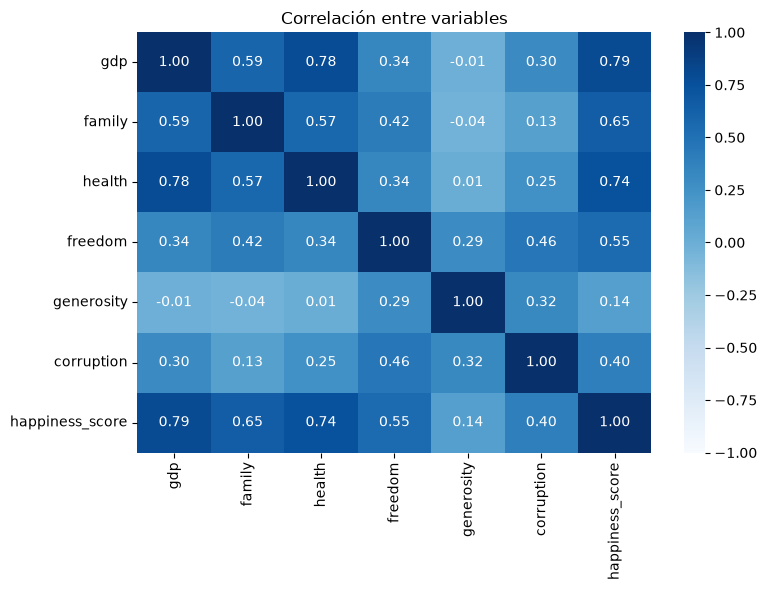

In [3]:
NUMERICAS = ["gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[NUMERICAS].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.tight_layout()
plt.show()

In [4]:
# Correlación de cada variable con el puntaje, de mayor a menor
df[NUMERICAS].corr()["happiness_score"].drop("happiness_score").sort_values(ascending=False).round(3)

gdp           0.789
health        0.742
family        0.649
freedom       0.551
corruption    0.397
generosity    0.138
Name: happiness_score, dtype: float64

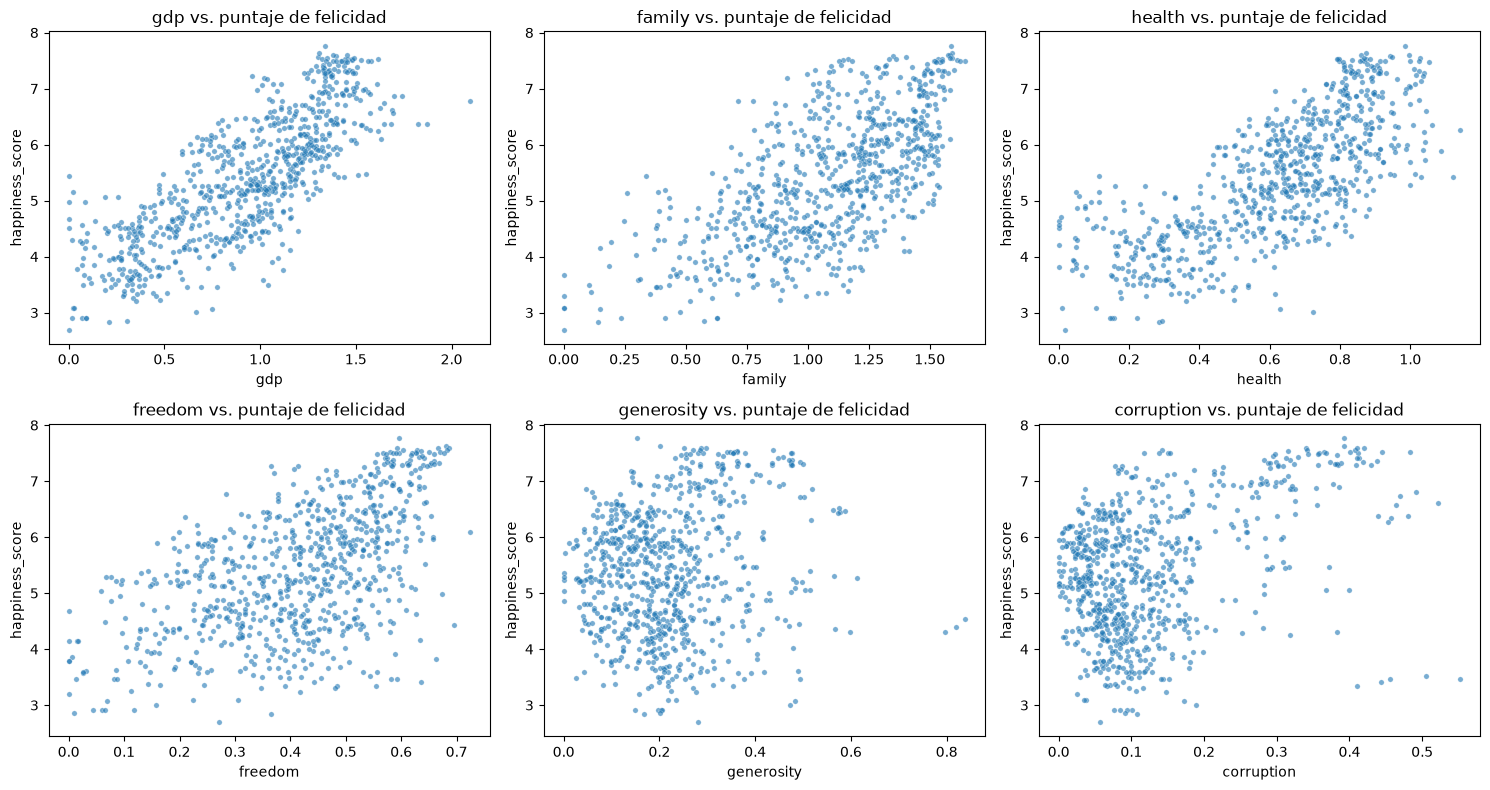

In [5]:
CANDIDATAS = ["gdp", "family", "health", "freedom", "generosity", "corruption"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), CANDIDATAS):
    sns.scatterplot(data=df, x=col, y="happiness_score", ax=ax, s=15, alpha=0.6)
    ax.set_title(f"{col} vs. puntaje de felicidad")
plt.tight_layout()
plt.show()

**Lo que se ve:**

- `gdp` (0.79), `health` (0.74) y `family` (0.65) tienen la relación más fuerte con el puntaje: a mayor valor, mayor felicidad, y los puntos forman una franja clara.
- `freedom` (0.55) tiene una relación media.
- `corruption` (0.40) tiene una relación baja y `generosity` (0.14) casi ninguna; sus puntos están mucho más dispersos.
- `gdp` y `health` también están muy relacionadas entre sí (los países más ricos tienen mayor esperanza de vida).

## 4. Selección de características

**Características elegidas (6):** `gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`

**Justificación:**

| Columna | ¿Se usa? | Por qué |
|---|---|---|
| `gdp`, `family`, `health`, `freedom` | Sí | Relación media o fuerte con el puntaje |
| `generosity`, `corruption` | Sí | Relación baja, pero son parte del contrato del evento de Kafka y de los 6 factores con los que el informe explica la felicidad; aportan un poco y no perjudican a un modelo simple |
| `happiness_score` | **No, es el objetivo** | Es lo que se quiere predecir. Usarlo como entrada sería fuga del objetivo. En el evento de Kafka viaja como `actual_happiness_score`, solo para comparar después |
| `country` | No | Es una etiqueta con 164 valores distintos y unas 5 filas por país. El modelo memorizaría países en vez de aprender de los indicadores, y fallaría con un país que no haya visto |
| `year` | No | No es una característica del país. Un modelo que dependa del año no sirve para eventos de años nuevos |

**Fuga del objetivo:** el ranking y el residuo de distopía, que se derivan del puntaje, ya se descartaron en la limpieza.

**Datos categóricos:** la única columna categórica es `country` y no se usa como característica, así que no hace falta codificar nada.

In [6]:
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
TARGET = "happiness_score"

X = df[FEATURES]
y = df[TARGET]
print("X:", X.shape, "  y:", y.shape)

X: (782, 6)   y: (782,)


## 5. División en entrenamiento y prueba (70% / 30%)

El modelo aprende con el 70% y se evalúa con el 30% que nunca vio. `random_state=42` fija la división para que cualquiera que ejecute el notebook obtenga exactamente los mismos resultados (reproducibilidad).

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print("Entrenamiento:", X_train.shape[0], "filas")
print("Prueba:", X_test.shape[0], "filas")

Entrenamiento: 547 filas
Prueba: 235 filas


## 6. Pipeline: escalado + regresión lineal

**Modelo elegido:** regresión lineal, el más simple de los que sugiere el taller. Sus coeficientes se pueden leer y explicar.

**Escalado (`StandardScaler`):** pone todas las características en la misma escala (promedio 0, desviación 1). En una regresión lineal el escalado **no cambia las predicciones**; se incluye porque así los coeficientes son comparables entre sí y se ve cuál variable pesa más.

**Por qué un `Pipeline`:** el escalador "aprende" el promedio y la desviación de los datos de entrenamiento. Al meter escalador y modelo en un solo objeto, se guardan juntos en `model.pkl`, y el consumidor de Kafka aplicará exactamente el mismo preprocesamiento del entrenamiento sin repetir código. Es lo que pide el taller.

El escalador se ajusta **solo con los datos de entrenamiento**, para que no "vea" información de los datos de prueba.

In [8]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

pipeline.fit(X_train, y_train)
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['gdp','family','health','freedom','generosity','corruption']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 7. Evaluación del modelo

- **MAE** (error absoluto medio): en promedio, cuántos puntos se equivoca la predicción.
- **RMSE** (raíz del error cuadrático medio): parecido al MAE, pero castiga más los errores grandes.
- **R²**: qué proporción de la variación del puntaje logra explicar el modelo (1 sería perfecto).

In [9]:
def evaluar(nombre, X_parte, y_parte):
    pred = pipeline.predict(X_parte)
    return {
        "conjunto": nombre,
        "MAE": mean_absolute_error(y_parte, pred),
        "RMSE": np.sqrt(mean_squared_error(y_parte, pred)),
        "R2": r2_score(y_parte, pred),
    }

metricas = pd.DataFrame([
    evaluar("entrenamiento (70%)", X_train, y_train),
    evaluar("prueba (30%)", X_test, y_test),
]).set_index("conjunto").round(4)
metricas

,MAE,RMSE,R2
conjunto,,,
entrenamiento (70%),0.4172,0.5327,0.7780
prueba (30%),0.4486,0.5843,0.7266


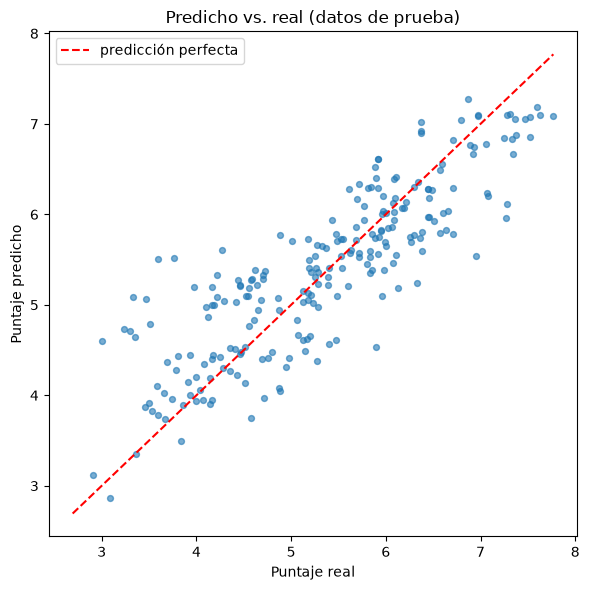

In [10]:
y_pred = pipeline.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=18, alpha=0.6)
limites = [y.min(), y.max()]
plt.plot(limites, limites, color="red", linestyle="--", label="predicción perfecta")
plt.xlabel("Puntaje real")
plt.ylabel("Puntaje predicho")
plt.title("Predicho vs. real (datos de prueba)")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Peso de cada característica (coeficientes sobre datos escalados, por eso son comparables)
coeficientes = pd.Series(pipeline.named_steps["model"].coef_, index=FEATURES).sort_values(ascending=False).round(4)
print("Intercepto:", round(pipeline.named_steps["model"].intercept_, 4))
coeficientes

Intercepto: 5.3864


gdp           0.4520
freedom       0.2512
health        0.2418
family        0.2092
corruption    0.1085
generosity    0.0495
dtype: float64

**Lo que se ve:**

- Las métricas de prueba son un poco peores que las de entrenamiento (MAE 0.45 frente a 0.42; R² 0.73 frente a 0.78). Es lo normal: el modelo siempre acierta algo más con los datos que ya vio. La diferencia es pequeña, así que no hay un sobreajuste importante.
- En los datos de prueba el modelo se equivoca, en promedio, 0.45 puntos en una escala que va de 2.7 a 7.8, y explica cerca del 73% de la variación del puntaje.
- `gdp` es la característica con más peso, seguida por `freedom`, `health` y `family`. `corruption` y `generosity` pesan poco, como anticipaban las correlaciones.

Para el objetivo del taller (un pipeline integrado, no la máxima precisión) este resultado es suficiente.

## 8. Guardar el pipeline como `model.pkl`

Se guarda el pipeline completo (escalador + modelo). El orden de las características queda guardado dentro del propio pipeline, en `feature_names_in_`.

In [12]:
RUTA_MODELO = "../models/model.pkl"
joblib.dump(pipeline, RUTA_MODELO)
print("Modelo guardado en:", RUTA_MODELO)

Modelo guardado en: ../models/model.pkl


## 9. Prueba: cargar el modelo y predecir un evento

Se simula lo que hará el consumidor de Kafka: cargar `model.pkl`, recibir un evento con el formato JSON del taller y predecir. `actual_happiness_score` **no** entra al modelo; solo se usa para calcular el error.

In [13]:
modelo_cargado = joblib.load(RUTA_MODELO)
print("Orden de características que espera el modelo:", list(modelo_cargado.feature_names_in_))

# El evento de ejemplo que trae el enunciado del taller
evento = {
    "event_id": "E001", "country": "Colombia", "year": 2019,
    "gdp": 1.2, "family": 0.8, "health": 0.9, "freedom": 0.6,
    "generosity": 0.3, "corruption": 0.1,
    "actual_happiness_score": 6.2,
    "event_time": "2026-10-30T15:30:00",
}

entrada = pd.DataFrame([evento])[list(modelo_cargado.feature_names_in_)]
prediccion = modelo_cargado.predict(entrada)[0]

print("Puntaje real:     ", evento["actual_happiness_score"])
print("Puntaje predicho: ", round(prediccion, 3))
print("Error:            ", round(evento["actual_happiness_score"] - prediccion, 3))

Orden de características que espera el modelo: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
Puntaje real:      6.2
Puntaje predicho:  6.117
Error:             0.083


## 10. Resumen

| Decisión | Elección | Justificación |
|---|---|---|
| Características | `gdp`, `family`, `health`, `freedom`, `generosity`, `corruption` | Son los 6 factores del informe y los campos numéricos del contrato del evento |
| Excluidas | `country`, `year` | Etiqueta de alta cardinalidad y variable que no describe al país |
| Fuga del objetivo | El puntaje, el ranking y el residuo de distopía no son entradas | Se derivan de lo que se quiere predecir |
| División | 70% / 30%, `random_state=42` | Sugerencia del taller; resultados reproducibles |
| Modelo | Regresión lineal | El más simple; el foco es el pipeline |
| Preprocesamiento | `StandardScaler` dentro de un `Pipeline` | Se serializa junto al modelo; mismo preprocesamiento en el consumidor |
| Salida | `models/model.pkl` | Pipeline completo, listo para el consumidor de Kafka |